# Integrated Urban Infrastructure Analysis — Corrected Final Notebook

**Project:** Integrated Urban Risk Analytics and Resource Prioritization System  
**Input:** `data/processed/infrastructure/integrated_infrastructure_experiments/integrated_infrastructure_road_grid_1km.csv`

This notebook consumes the already-created integrated 1 km grid. It audits the data, analyses coverage, compares K-Means configurations, fits the selected model, and saves a dashboard-ready file for all grid cells.

**Important limitations**
- The 791 grid cells include 416 cells with mapped infrastructure records and 375 without mapped infrastructure records in the current source data.
- K-Means is fitted only on the 416 infrastructure-present cells. The other 375 are retained separately and are not forced into a cluster.
- Clusters describe patterns in mapped infrastructure and road records. They are not validated risk labels, safety ratings, or predictions.
- Road counts and lengths use representative points, not full road geometry. They do not measure network connectivity, route distance, or emergency travel time.
- No mapped record does not prove that a real-world facility or road is absent.


## 1. Imports and configuration

In [1]:
from pathlib import Path
import os, json, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

PROJECT_DIR = Path(r"C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics")
if not PROJECT_DIR.exists():
    raise FileNotFoundError(f"Project folder not found: {PROJECT_DIR}")
os.chdir(PROJECT_DIR)

INTEGRATED_DIR = PROJECT_DIR / "data/processed/infrastructure/integrated_infrastructure_experiments"
CLUSTER_DIR = INTEGRATED_DIR / "clustering_experiments"
MODEL_DIR = PROJECT_DIR / "models/infrastructure"
INPUT_FILE = INTEGRATED_DIR / "integrated_infrastructure_road_grid_1km.csv"

CLUSTER_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_DIR)
print("Input exists:", INPUT_FILE.exists())
print("Output:", CLUSTER_DIR)
print("Models:", MODEL_DIR)

if not INPUT_FILE.exists():
    raise FileNotFoundError(f"Integrated CSV not found: {INPUT_FILE}")


Project: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics
Input exists: True
Output: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\infrastructure\integrated_infrastructure_experiments\clustering_experiments
Models: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\models\infrastructure


## 2. Load and audit the integrated grid

In [2]:
integrated = pd.read_csv(INPUT_FILE)

required = [
    "grid_id", "cell_center_latitude", "cell_center_longitude",
    "infra_building_count", "infra_hospital_count", "infra_fire_station_count",
    "road_representative_point_count", "road_segment_length_sum_km",
    "unique_road_types", "total_infrastructure_records"
]
missing = [c for c in required if c not in integrated.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

numeric = [c for c in required if c != "grid_id"]
for col in numeric:
    integrated[col] = pd.to_numeric(integrated[col], errors="coerce")

if integrated["grid_id"].duplicated().any():
    raise ValueError("Duplicate grid_id values found.")
if integrated[required].isna().any().any():
    raise ValueError("Missing values found in required columns.")
if (integrated[numeric] < 0).any().any():
    raise ValueError("Negative values found in required numeric columns.")

print("Shape:", integrated.shape)
print("Duplicate grid IDs:", integrated["grid_id"].duplicated().sum())
display(integrated[numeric].describe().round(2).T)


Shape: (791, 26)
Duplicate grid IDs: 0


,count,mean,std,min,25%,50%,75%,max
cell_center_latitude,791.0,17.43,0.07,17.26,17.37,17.44,17.48,17.55
cell_center_longitude,791.0,78.45,0.09,78.24,78.39,78.46,78.53,78.63
infra_building_count,791.0,1.27,4.69,0.00,0.00,0.00,1.00,85.00
infra_hospital_count,791.0,1.36,2.55,0.00,0.00,0.00,2.00,26.00
infra_fire_station_count,791.0,0.01,0.09,0.00,0.00,0.00,0.00,1.00
road_representative_point_count,791.0,118.13,87.06,0.00,34.00,114.00,189.00,415.00
road_segment_length_sum_km,791.0,15.97,10.10,0.00,6.83,16.31,24.54,44.32
unique_road_types,791.0,2.53,1.23,0.00,2.00,2.00,3.00,6.00
total_infrastructure_records,791.0,2.63,5.67,0.00,0.00,1.00,3.00,85.00


## 3. Data availability across grid cells

In [3]:
integrated["has_infrastructure_records"] = integrated["total_infrastructure_records"] > 0
integrated["has_road_records"] = integrated["road_representative_point_count"] > 0

both = integrated["has_infrastructure_records"] & integrated["has_road_records"]
infra_only = integrated["has_infrastructure_records"] & ~integrated["has_road_records"]
roads_only = ~integrated["has_infrastructure_records"] & integrated["has_road_records"]
neither = ~integrated["has_infrastructure_records"] & ~integrated["has_road_records"]

availability = pd.DataFrame({
    "condition": ["Both sources represented", "Infrastructure only", "Roads only", "Neither source represented"],
    "cells": [int(both.sum()), int(infra_only.sum()), int(roads_only.sum()), int(neither.sum())]
})
availability["percentage"] = (availability["cells"] / len(integrated) * 100).round(2)
display(availability)

infra_present = integrated.loc[integrated["has_infrastructure_records"]].copy()
no_infra = integrated.loc[~integrated["has_infrastructure_records"]].copy()

print("All cells:", len(integrated))
print("Infrastructure-present cells:", len(infra_present))
print("No mapped infrastructure records:", len(no_infra))


,condition,cells,percentage
0,Both sources represented,388,49.05
1,Infrastructure only,28,3.54
2,Roads only,375,47.41
3,Neither source represented,0,0.00


All cells: 791
Infrastructure-present cells: 416
No mapped infrastructure records: 375


## 4. Diagnostic categories for further investigation

Quartiles are descriptive thresholds, not official standards or risk cut-offs. The infrastructure threshold is calculated only among cells with positive infrastructure counts.

In [15]:
positive_infra = integrated.loc[
    integrated["total_infrastructure_records"] > 0,
    "total_infrastructure_records"
]
if positive_infra.empty:
    raise ValueError("No positive infrastructure counts found.")

infra_q1 = float(positive_infra.quantile(0.25))
road_q1 = float(integrated["road_representative_point_count"].quantile(0.25))

no_mapped_infra = integrated["total_infrastructure_records"] == 0
low_infra = (
    (integrated["total_infrastructure_records"] > 0)
    & (integrated["total_infrastructure_records"] <= infra_q1)
)
low_roads = integrated["road_representative_point_count"] <= road_q1

conditions = [
    no_mapped_infra,
    low_infra & low_roads,
    low_infra,
    low_roads
]
choices = [
    "No mapped infrastructure",
    "Both relatively low",
    "Low infrastructure only",
    "Low road representation only"
]

integrated["diagnostic_category"] = np.select(
    conditions, choices, default="Neither relatively low"
)

print("Infrastructure Q1:", infra_q1)
print("Road representation Q1:", road_q1)
display(
    integrated["diagnostic_category"]
    .value_counts()
    .rename_axis("diagnostic_category")
    .to_frame("cells")
)


Infrastructure Q1: 1.0
Road representation Q1: 34.0


,cells
diagnostic_category,
No mapped infrastructure,375
Neither relatively low,262
Low infrastructure only,88
Both relatively low,37
Low road representation only,29


## 5. Exploratory visualisation

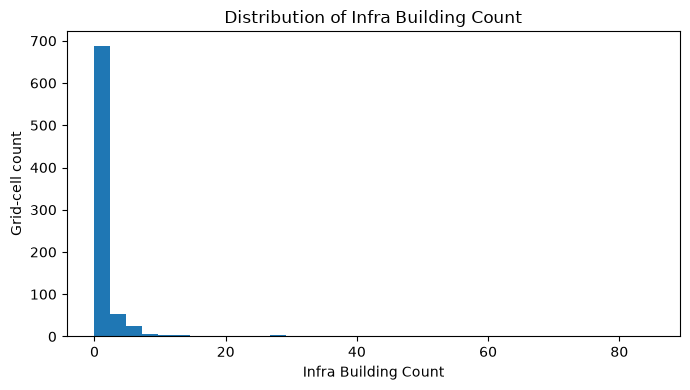

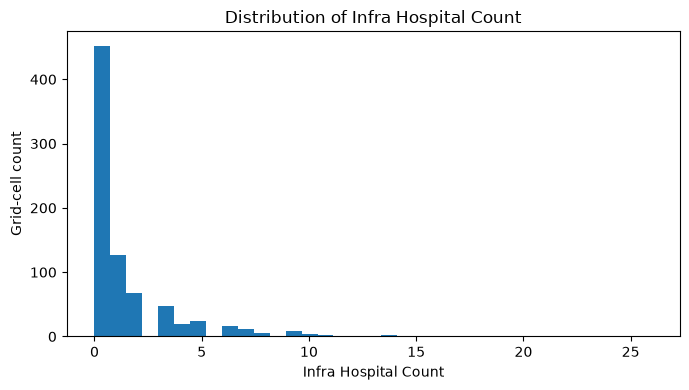

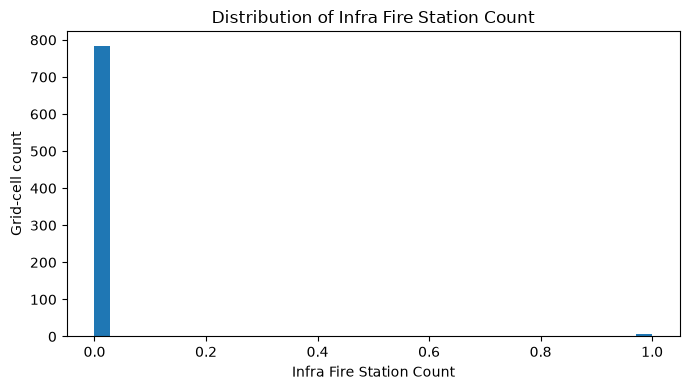

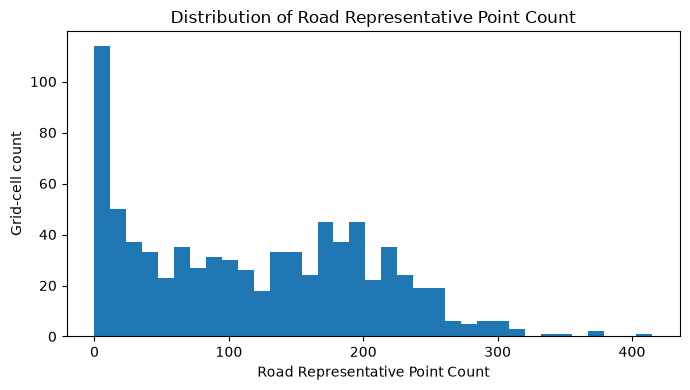

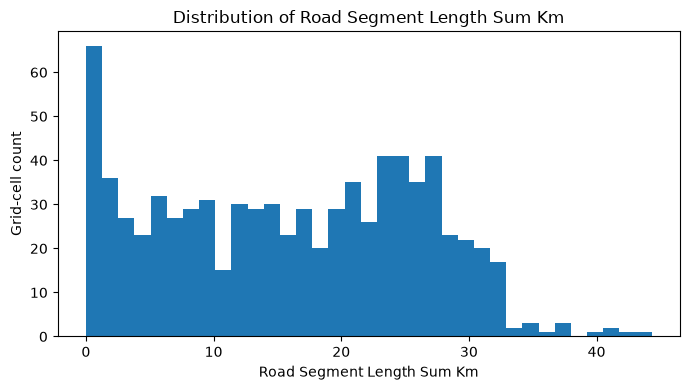

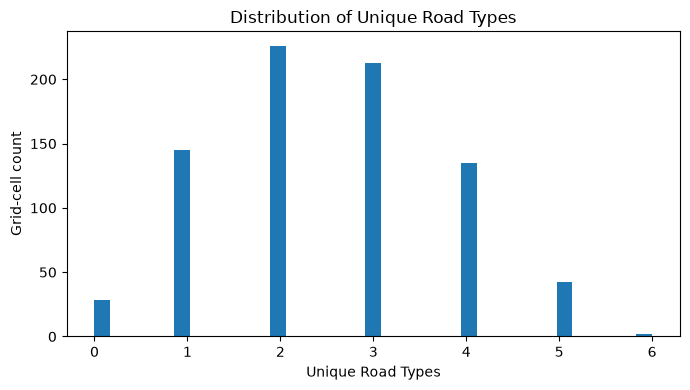

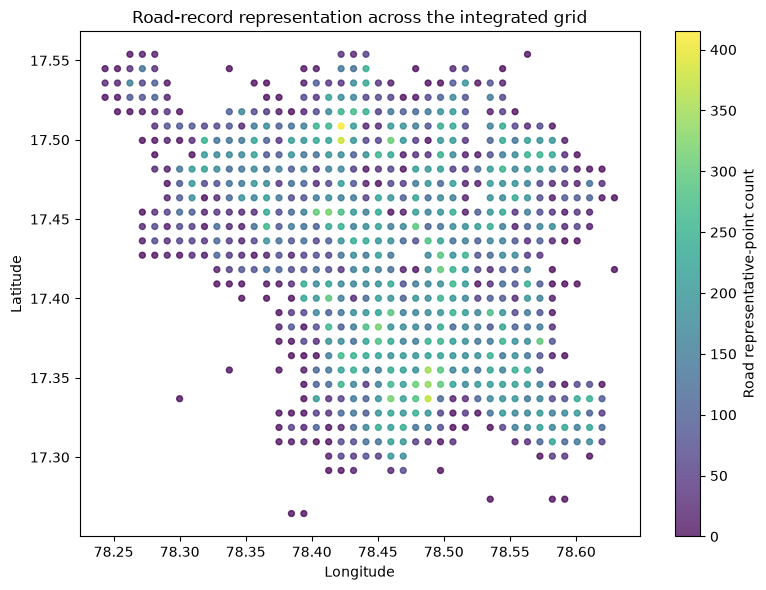

In [16]:
plot_features = [
    "infra_building_count", "infra_hospital_count", "infra_fire_station_count",
    "road_representative_point_count", "road_segment_length_sum_km", "unique_road_types"
]

for col in plot_features:
    plt.figure(figsize=(7, 4))
    plt.hist(integrated[col], bins=35)
    plt.title(f"Distribution of {col.replace('_', ' ').title()}")
    plt.xlabel(col.replace("_", " ").title())
    plt.ylabel("Grid-cell count")
    plt.tight_layout()
    plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(
    integrated["cell_center_longitude"],
    integrated["cell_center_latitude"],
    c=integrated["road_representative_point_count"],
    s=18,
    alpha=0.75
)
plt.colorbar(label="Road representative-point count")
plt.title("Road-record representation across the integrated grid")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()


## 6. Prepare clustering features

We compare:
- all six features, including fire-station count;
- five features, excluding fire-station count.

The fire-station feature is sparse in the current data (seven mapped fire-station records), and the earlier three-cluster solution isolated those seven cells. Fire-station counts will remain available for dashboard display, but are excluded from the primary segmentation.

`log1p` reduces skew. `StandardScaler` puts the transformed features on comparable scales.

In [6]:
FEATURES_ALL = [
    "infra_building_count", "infra_hospital_count", "infra_fire_station_count",
    "road_representative_point_count", "road_segment_length_sum_km", "unique_road_types"
]
FEATURES_WITHOUT_FIRE = [
    "infra_building_count", "infra_hospital_count",
    "road_representative_point_count", "road_segment_length_sum_km", "unique_road_types"
]

def prepare_features(data, columns):
    X = data[columns].copy()
    if X.isna().any().any():
        raise ValueError("Missing clustering feature values.")
    if (X < 0).any().any():
        raise ValueError("Negative values found; log1p requires non-negative values.")
    X_log = np.log1p(X)
    scaler = StandardScaler()
    return scaler.fit_transform(X_log), scaler

print("All features:", FEATURES_ALL)
print("Primary feature set:", FEATURES_WITHOUT_FIRE)


All features: ['infra_building_count', 'infra_hospital_count', 'infra_fire_station_count', 'road_representative_point_count', 'road_segment_length_sum_km', 'unique_road_types']
Primary feature set: ['infra_building_count', 'infra_hospital_count', 'road_representative_point_count', 'road_segment_length_sum_km', 'unique_road_types']


## 7. Compare K-Means configurations

K-Means is evaluated for k=2 through k=8 on all 791 cells and on the 416 infrastructure-present cells. Internal metrics support comparison but do not prove real-world risk validity.

In [7]:
def compare_kmeans(data, dataset_name):
    rows = []
    feature_sets = {
        "all_six": FEATURES_ALL,
        "without_fire_station": FEATURES_WITHOUT_FIRE
    }

    for feature_name, columns in feature_sets.items():
        X_scaled, _ = prepare_features(data, columns)

        for k in range(2, 9):
            model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
            labels = model.fit_predict(X_scaled)

            rows.append({
                "dataset": dataset_name,
                "feature_set": feature_name,
                "algorithm": "KMeans",
                "k": k,
                "silhouette": silhouette_score(X_scaled, labels),
                "davies_bouldin": davies_bouldin_score(X_scaled, labels),
                "calinski_harabasz": calinski_harabasz_score(X_scaled, labels)
            })
    return pd.DataFrame(rows)

results_all = compare_kmeans(integrated, "all_791_cells")
results_infra = compare_kmeans(infra_present, "infrastructure_present_416_cells")
kmeans_results = pd.concat([results_all, results_infra], ignore_index=True)

kmeans_results.to_csv(CLUSTER_DIR / "integrated_kmeans_comparison_corrected.csv", index=False)

display(
    kmeans_results.sort_values(
        ["dataset", "silhouette"], ascending=[True, False]
    ).round(4)
)


,dataset,feature_set,algorithm,k,silhouette,davies_bouldin,calinski_harabasz
1,all_791_cells,all_six,KMeans,3,0.3831,0.7922,380.7947
7,all_791_cells,without_fire_station,KMeans,2,0.3788,1.0109,506.3955
2,all_791_cells,all_six,KMeans,4,0.3719,0.8534,491.1653
8,all_791_cells,without_fire_station,KMeans,3,0.3688,1.0197,558.9216
0,all_791_cells,all_six,KMeans,2,0.3677,1.0648,381.2182
3,all_791_cells,all_six,KMeans,5,0.3259,0.9163,479.0268
9,all_791_cells,without_fire_station,KMeans,4,0.3245,1.0545,499.9538
5,all_791_cells,all_six,KMeans,7,0.3156,0.9501,480.1025
6,all_791_cells,all_six,KMeans,8,0.3137,0.9565,474.7393
12,all_791_cells,without_fire_station,KMeans,7,0.3127,1.0438,458.8328


## 8. Compare metric curves

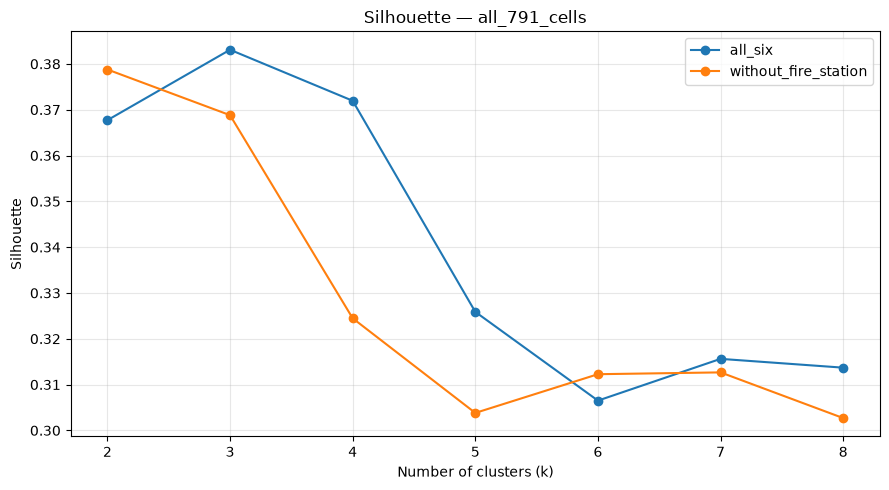

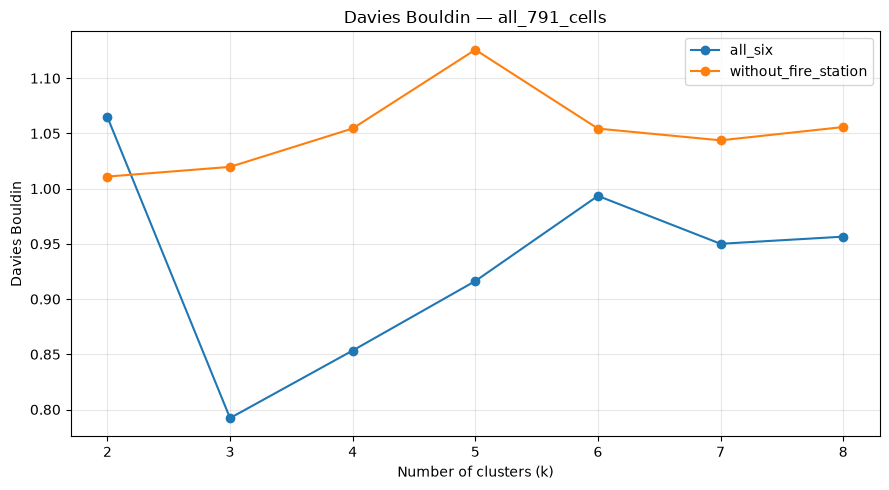

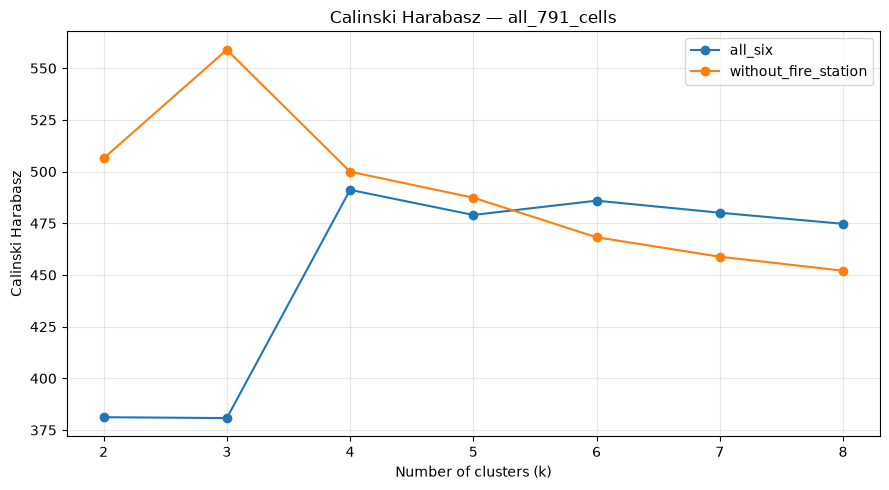

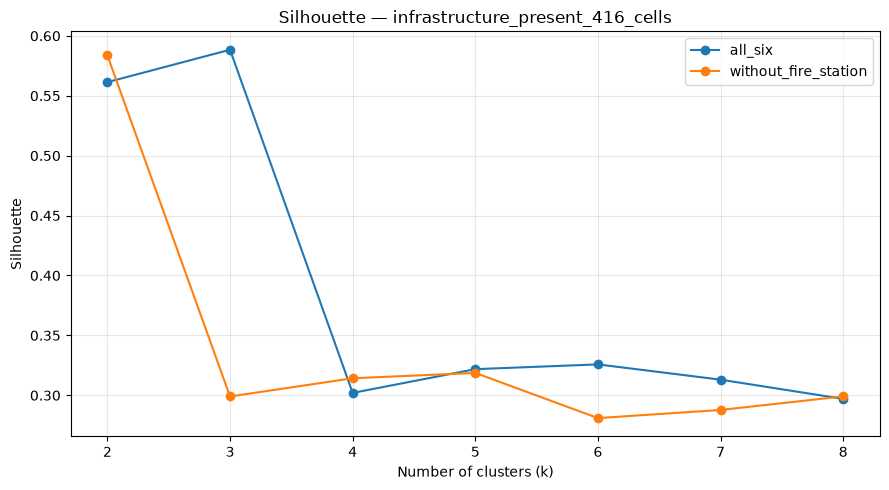

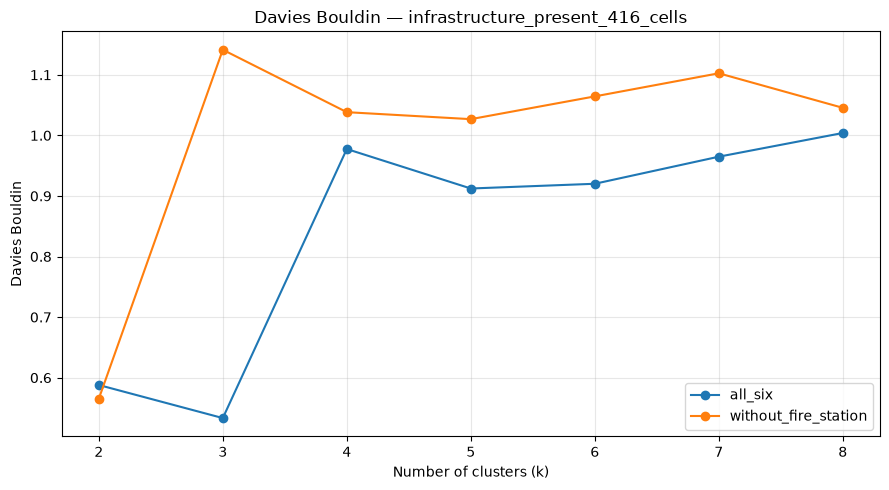

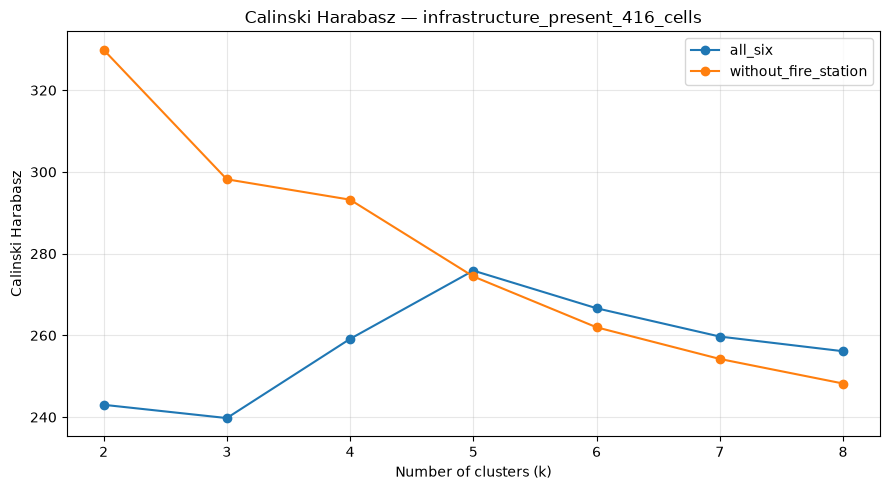

In [8]:
for dataset_name in kmeans_results["dataset"].unique():
    subset = kmeans_results[kmeans_results["dataset"] == dataset_name]

    for metric in ["silhouette", "davies_bouldin", "calinski_harabasz"]:
        plt.figure(figsize=(9, 5))
        for feature_set, group in subset.groupby("feature_set"):
            group = group.sort_values("k")
            plt.plot(group["k"], group[metric], marker="o", label=feature_set)

        plt.title(f"{metric.replace('_', ' ').title()} — {dataset_name}")
        plt.xlabel("Number of clusters (k)")
        plt.ylabel(metric.replace("_", " ").title())
        plt.xticks(range(2, 9))
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.show()


## 9. Fit the selected final model

**Selected configuration:** K-Means, k=2, five features excluding fire-station count, fitted on the 416 infrastructure-present cells.

Previously observed comparison metrics for this configuration were:
- Silhouette: 0.583682
- Davies-Bouldin: 0.565249
- Calinski-Harabasz: 329.899821

The notebook recomputes the metrics from the current CSV rather than hardcoding them. Cluster numbers are arbitrary, so the descriptions are assigned by comparing the clusters' mean road-record counts.

In [9]:
FINAL_FEATURES = FEATURES_WITHOUT_FIRE
FINAL_K = 2

X_final_log = np.log1p(infra_present[FINAL_FEATURES])
final_scaler = StandardScaler()
X_final_scaled = final_scaler.fit_transform(X_final_log)

final_kmeans = KMeans(
    n_clusters=FINAL_K,
    random_state=RANDOM_STATE,
    n_init=20
)
final_labels = final_kmeans.fit_predict(X_final_scaled)

infra_clustered = infra_present.copy()
infra_clustered["kmeans_cluster"] = final_labels

final_metrics = {
    "silhouette": float(silhouette_score(X_final_scaled, final_labels)),
    "davies_bouldin": float(davies_bouldin_score(X_final_scaled, final_labels)),
    "calinski_harabasz": float(calinski_harabasz_score(X_final_scaled, final_labels))
}

print("Final metrics:")
display(pd.DataFrame([final_metrics]).round(6))

print("Cluster sizes:")
display(infra_clustered["kmeans_cluster"].value_counts().sort_index().to_frame("cells"))

print("Cluster percentages:")
display(
    (infra_clustered["kmeans_cluster"].value_counts(normalize=True).sort_index() * 100)
    .round(2).to_frame("percentage")
)


Final metrics:


,silhouette,davies_bouldin,calinski_harabasz
0,0.583682,0.565249,329.899821


Cluster sizes:


,cells
kmeans_cluster,
0,375
1,41


Cluster percentages:


,percentage
kmeans_cluster,
0,90.14
1,9.86


## 10. Inspect and describe the final clusters

In [10]:
PROFILE_FEATURES = [
    "infra_building_count", "infra_hospital_count", "infra_fire_station_count",
    "road_representative_point_count", "road_segment_length_sum_km", "unique_road_types"
]

print("Mean profiles:")
display(infra_clustered.groupby("kmeans_cluster")[PROFILE_FEATURES].mean().round(2))

print("Median profiles:")
display(infra_clustered.groupby("kmeans_cluster")[PROFILE_FEATURES].median().round(2))

mean_roads = infra_clustered.groupby("kmeans_cluster")[
    "road_representative_point_count"
].mean()

higher_road_cluster = int(mean_roads.idxmax())
lower_road_cluster = int(mean_roads.idxmin())

cluster_descriptions = {
    higher_road_cluster: "Higher mapped road representation",
    lower_road_cluster: "Lower mapped road representation"
}

infra_clustered["cluster_description"] = (
    infra_clustered["kmeans_cluster"].map(cluster_descriptions)
)

print("Higher-road-representation cluster:", higher_road_cluster)
print("Lower-road-representation cluster:", lower_road_cluster)


Mean profiles:


,infra_building_count,infra_hospital_count,infra_fire_station_count,road_representative_point_count,road_segment_length_sum_km,unique_road_types
kmeans_cluster,,,,,,
0,2.66,2.70,0.02,157.83,20.85,3.21
1,0.10,1.49,0.00,2.49,0.59,0.41


Median profiles:


,infra_building_count,infra_hospital_count,infra_fire_station_count,road_representative_point_count,road_segment_length_sum_km,unique_road_types
kmeans_cluster,,,,,,
0,1.0,2.0,0.0,168.0,22.45,3.0
1,0.0,1.0,0.0,0.0,0.00,0.0


Higher-road-representation cluster: 0
Lower-road-representation cluster: 1


## 11. Create the final dashboard-ready output for all 791 cells

The model is fitted only on the 416 infrastructure-present cells. The other 375 cells receive a separate data-availability category and remain unclustered.

In [11]:
final_output = integrated.copy()

final_output["kmeans_cluster"] = pd.Series(
    pd.NA, index=final_output.index, dtype="Int64"
)
final_output["cluster_description"] = "No mapped infrastructure records"
final_output["dashboard_category"] = "No mapped infrastructure records"

cluster_lookup = infra_clustered.set_index("grid_id")[
    ["kmeans_cluster", "cluster_description"]
]

infra_mask = final_output["total_infrastructure_records"] > 0

final_output.loc[infra_mask, "kmeans_cluster"] = (
    final_output.loc[infra_mask, "grid_id"]
    .map(cluster_lookup["kmeans_cluster"])
    .astype("Int64")
)

final_output.loc[infra_mask, "cluster_description"] = (
    final_output.loc[infra_mask, "grid_id"]
    .map(cluster_lookup["cluster_description"])
)

final_output.loc[infra_mask, "dashboard_category"] = (
    final_output.loc[infra_mask, "grid_id"]
    .map(cluster_lookup["cluster_description"])
)

final_output["contains_mapped_fire_station"] = (
    final_output["infra_fire_station_count"] > 0
)

if final_output.loc[infra_mask, "kmeans_cluster"].isna().any():
    raise ValueError("An infrastructure-present cell did not receive a cluster.")
if final_output.loc[~infra_mask, "kmeans_cluster"].notna().any():
    raise ValueError("A cell without mapped infrastructure was assigned a K-Means cluster.")

dashboard_summary = (
    final_output["dashboard_category"]
    .value_counts()
    .rename_axis("dashboard_category")
    .reset_index(name="cells")
)
dashboard_summary["percentage"] = (
    dashboard_summary["cells"] / len(final_output) * 100
).round(2)
display(dashboard_summary)

print("Final output rows:", len(final_output))


,dashboard_category,cells,percentage
0,No mapped infrastructure records,375,47.41
1,Higher mapped road representation,375,47.41
2,Lower mapped road representation,41,5.18


Final output rows: 791


## 12. Map the exploratory segmentation

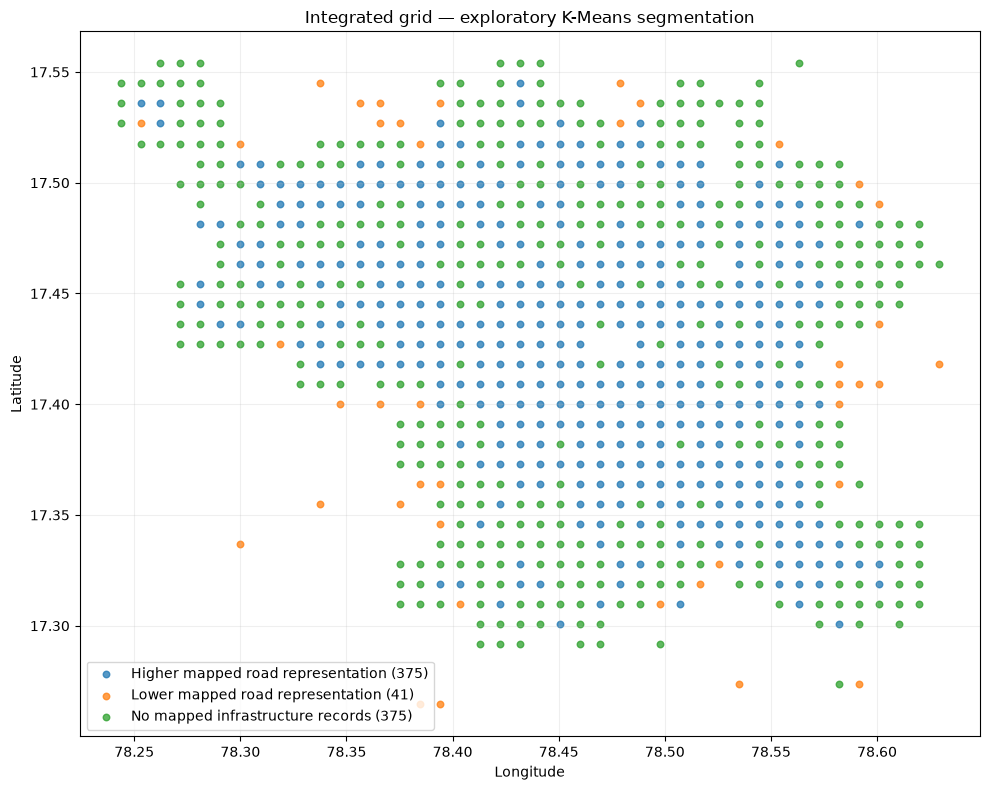

In [12]:
categories = [
    "Higher mapped road representation",
    "Lower mapped road representation",
    "No mapped infrastructure records"
]

plt.figure(figsize=(10, 8))
for category in categories:
    subset = final_output[final_output["dashboard_category"] == category]
    plt.scatter(
        subset["cell_center_longitude"],
        subset["cell_center_latitude"],
        s=22,
        alpha=0.75,
        label=f"{category} ({len(subset)})"
    )

plt.title("Integrated grid — exploratory K-Means segmentation")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()


## 13. Save the model, scaler, assignments, and summary

In [13]:
final_csv = CLUSTER_DIR / "integrated_grid_final_kmeans_2_dashboard_ready.csv"
infra_csv = CLUSTER_DIR / "infrastructure_present_416_final_kmeans_k2.csv"
model_path = MODEL_DIR / "integrated_infrastructure_kmeans_k2_final.joblib"
summary_path = CLUSTER_DIR / "integrated_infrastructure_final_summary.json"

final_output.to_csv(final_csv, index=False)
infra_clustered.to_csv(infra_csv, index=False)

artifact = {
    "model": final_kmeans,
    "scaler": final_scaler,
    "feature_columns": FINAL_FEATURES,
    "transformation": "numpy.log1p",
    "cluster_count": FINAL_K,
    "random_state": RANDOM_STATE,
    "n_init": 20,
    "training_population": "Infrastructure-present grid cells only",
    "cluster_descriptions": cluster_descriptions,
    "higher_road_representation_cluster": higher_road_cluster,
    "lower_road_representation_cluster": lower_road_cluster,
    "interpretation": "Exploratory segmentation, not validated risk labels."
}
joblib.dump(artifact, model_path)

summary = {
    "input_file": str(INPUT_FILE),
    "total_grid_cells": int(len(final_output)),
    "infrastructure_present_cells": int(len(infra_clustered)),
    "cells_without_mapped_infrastructure_records": int((~infra_mask).sum()),
    "algorithm": "KMeans",
    "selected_k": FINAL_K,
    "feature_columns": FINAL_FEATURES,
    "transformation": "log1p",
    "scaling": "StandardScaler",
    "random_state": RANDOM_STATE,
    "n_init": 20,
    "evaluation_metrics": final_metrics,
    "cluster_sizes": {
        str(int(k)): int(v)
        for k, v in infra_clustered["kmeans_cluster"].value_counts().sort_index().items()
    },
    "cluster_descriptions": {
        str(int(k)): v for k, v in cluster_descriptions.items()
    },
    "dashboard_category_counts": {
        str(k): int(v)
        for k, v in final_output["dashboard_category"].value_counts().items()
    },
    "validated_risk_labels_available": False,
    "road_geometry_available": False,
    "interpretation": (
        "Exploratory clustering of mapped infrastructure and road-record representation. "
        "No validated risk labels, road-network connectivity, or travel-time analysis."
    )
}

summary_path.write_text(json.dumps(summary, indent=4), encoding="utf-8")

print("Saved dashboard CSV:", final_csv)
print("Saved infrastructure-present CSV:", infra_csv)
print("Saved model artifact:", model_path)
print("Saved summary:", summary_path)


Saved dashboard CSV: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\infrastructure\integrated_infrastructure_experiments\clustering_experiments\integrated_grid_final_kmeans_2_dashboard_ready.csv
Saved infrastructure-present CSV: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\infrastructure\integrated_infrastructure_experiments\clustering_experiments\infrastructure_present_416_final_kmeans_k2.csv
Saved model artifact: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\models\infrastructure\integrated_infrastructure_kmeans_k2_final.joblib
Saved summary: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\infrastructure\integrated_infrastructure_experiments\clustering_experiments\integrated_infrastructure_final_summary.json


## 14. Verify saved files

In [14]:
verified = pd.read_csv(final_csv)
verified_model = joblib.load(model_path)
verified_summary = json.loads(summary_path.read_text(encoding="utf-8"))

print("Verified CSV shape:", verified.shape)
print("Dashboard categories:")
display(verified["dashboard_category"].value_counts().to_frame("cells"))

print("Saved model features:", verified_model["feature_columns"])
print("Saved cluster count:", verified_model["cluster_count"])
print("Saved metrics:", verified_summary["evaluation_metrics"])

assert len(verified) == len(integrated)
assert verified["grid_id"].is_unique
assert verified.loc[
    verified["total_infrastructure_records"] > 0, "kmeans_cluster"
].notna().all()
assert verified.loc[
    verified["total_infrastructure_records"] == 0, "kmeans_cluster"
].isna().all()

print("FINAL VERIFICATION PASSED.")


Verified CSV shape: (791, 33)
Dashboard categories:


,cells
dashboard_category,
No mapped infrastructure records,375
Higher mapped road representation,375
Lower mapped road representation,41


Saved model features: ['infra_building_count', 'infra_hospital_count', 'road_representative_point_count', 'road_segment_length_sum_km', 'unique_road_types']
Saved cluster count: 2
Saved metrics: {'silhouette': 0.5836824992935442, 'davies_bouldin': 0.5652490661856001, 'calinski_harabasz': 329.89982073601715}
FINAL VERIFICATION PASSED.


## 15. Final interpretation and limitations

The integrated grid contains 791 cells. The current source data has 416 cells with mapped infrastructure records and 375 cells without mapped infrastructure records.

K-Means was compared across k=2 to k=8 using all six features and a five-feature set. The selected exploratory segmentation uses two clusters and five features on the 416 infrastructure-present cells. Fire-station counts remain available as a separate attribute rather than driving the main clustering.

The two clusters describe higher and lower mapped road-record representation, alongside differences in mapped building and hospital counts. The other 375 cells are retained as a separate data-availability category and are not assigned a K-Means cluster.

These results can support exploratory spatial screening and resource-prioritization discussions. They do not establish actual urban risk, facility absence, service adequacy, emergency accessibility, or travel time. Those claims would require authoritative facility inventories, complete road geometry/network data, and independently verified risk observations.

### Main saved files
- `data/processed/infrastructure/integrated_infrastructure_experiments/clustering_experiments/integrated_grid_final_kmeans_2_dashboard_ready.csv`
- `data/processed/infrastructure/integrated_infrastructure_experiments/clustering_experiments/infrastructure_present_416_final_kmeans_k2.csv`
- `data/processed/infrastructure/integrated_infrastructure_experiments/clustering_experiments/integrated_infrastructure_final_summary.json`
- `models/infrastructure/integrated_infrastructure_kmeans_k2_final.joblib`

**Upstream dependency:** This notebook reads the integrated grid CSV created by your earlier integration workflow. It does not regenerate infrastructure-point preprocessing, road preprocessing, or the 1 km grid aggregation.
